# Vortex + XGBoost Machine Learning

### 4.1 Overview 

- The Vortex Indicator with XGBoost Strategy uses the Vortex Indicator to detect  - - - trend direction, enhanced by an XGBoost classifier to predict trend signals. A ------ bullish signal triggers a long position when + VI > -VI with XGBoost uptrend -    - - probability > 0.7. A bearish signal triggers a short position when -VI > +VI. ATR - - sets TP/SL levels, optimized for 1-minute candles with
- 5x leverage.

### 4.2 Model Type

Gradient Boosting is a powerful machine learning technique used for regression and classification problems. It builds an ensemble (collection) of decision trees in a sequential manner, where each new tree tries to correct the errors made by the previous ones.

### 4.2.1 Signal Generation
- • Bullish: +VI > -VI, XGBoost uptrend probability > 0.7. Triggers long.
- • Bearish: -VIt > +VIt, XGBoost downtrend probability > 0.7. Triggers short.
- • Example: Price = $100, + VI = 1.2, -VI = 0.8, XGBoost probability = 0.75. Open long.




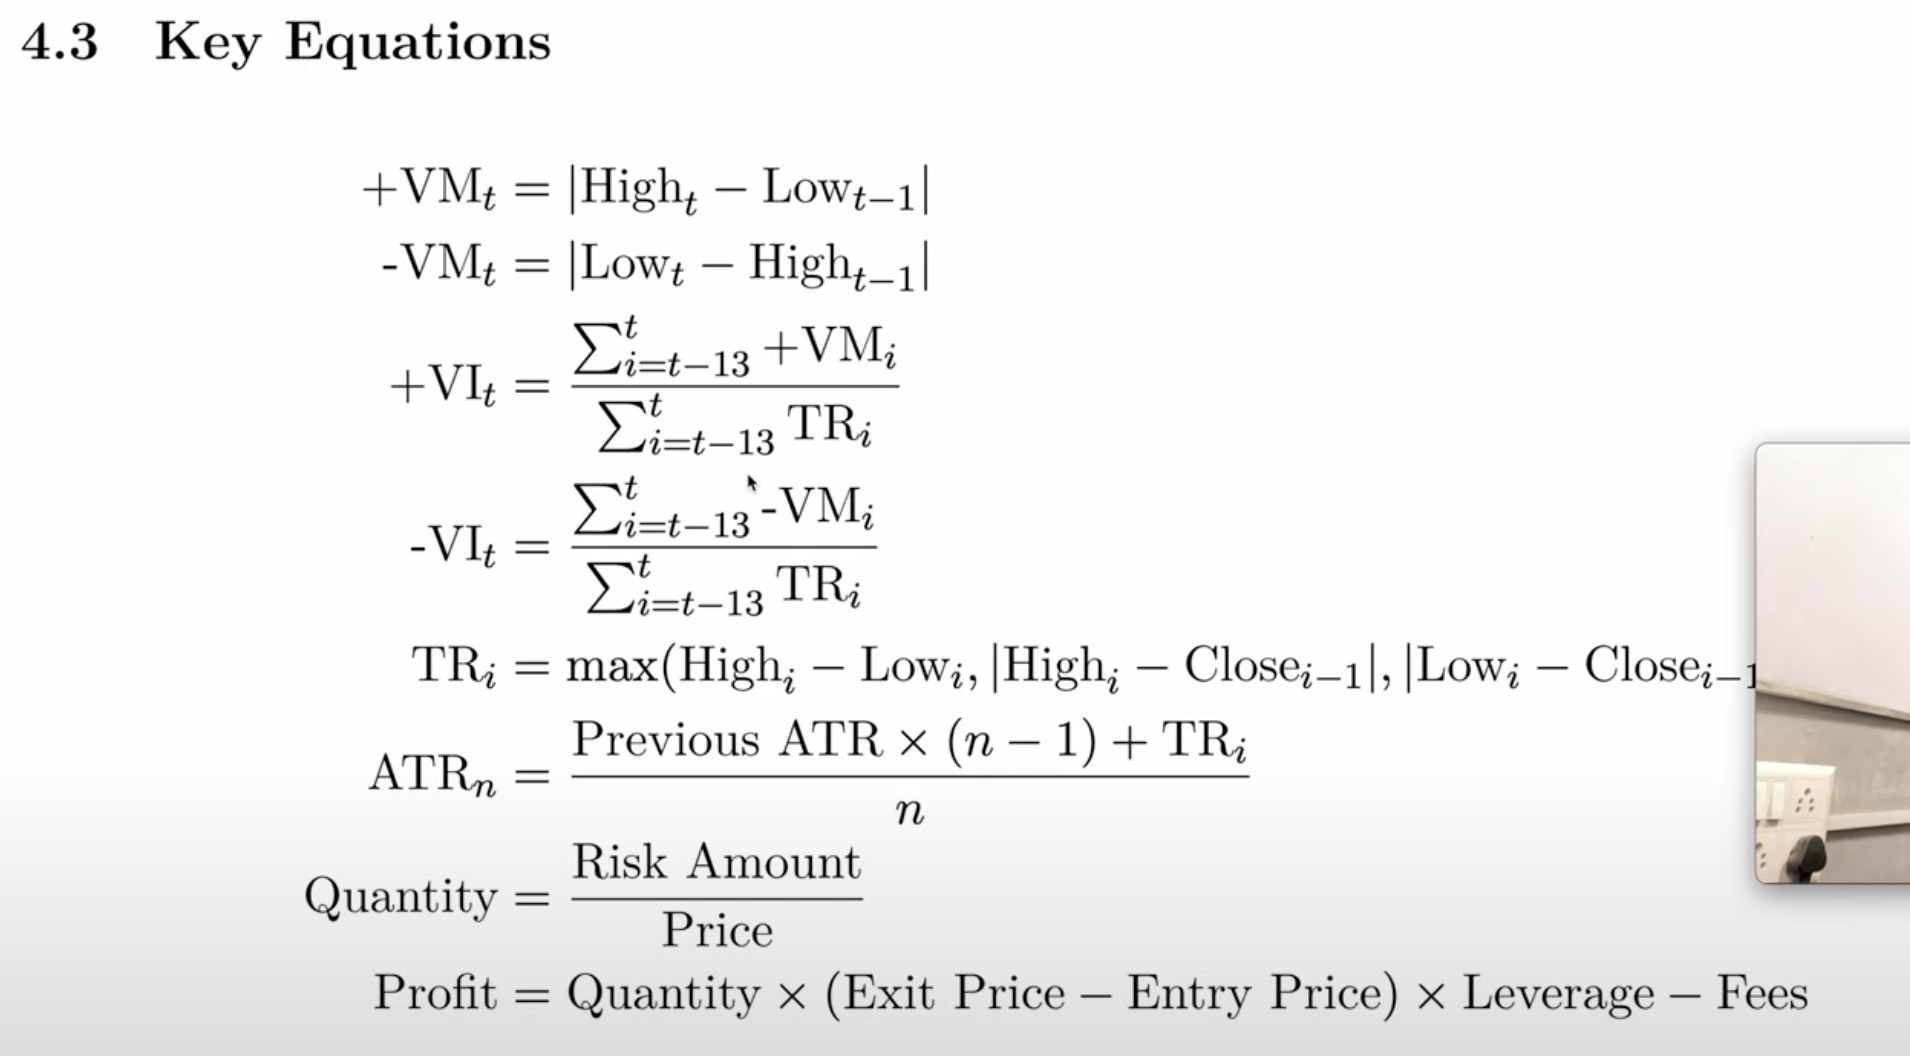

In [3]:
import ccxt.async_support as ccxt
import pandas as pd
import numpy as np
import asyncio
import logging
import nest_asyncio
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

logging.basicConfig(level = logging.INFO , format = '%(asctime)x - %(message)s')
logger = logging.getLogger(__name__)
nest_asyncio.apply()

In [4]:
SYMBOL = 'ALCH/USDT'
TIMEFRAME = '1m'
RISK_AMOUNT = 10.0
LEVERAGE = 5
VORTEX_PERIOD = 14
ATR_PERIOD = 14
TP_MULTIPLIER = 2.0
SL_MULTIPLIER = 1.0
FEE_RATE = 0.0002
MAX_POSITIONS = 2
CHECK_INTERVAL = 60
MODEL_THRESHOLD = 0.7

open_positions = []
scaler = StandardScaler()
model = XGBClassifier(n_estimators = 100 , random_state = 42)

In [5]:
async def fetch_data(exchange , symbol :str  , timeframe : str , limit : int = 100) -> pd.DataFrame:
    try:
        ohlcv = await exchange.fetch_ohlcv(symbol , timeframe , limit = limit)
        df = pd.DataFrame(ohlcv , columns = ['timestamp' , 'open' , 'high','low','close','volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'] , unit = 'ms')
        return df
    except Exception as e:
        logger.error(f"Error Fetching data: {str(e)}")
        return pd.DataFrame

In [6]:
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    try:
        df['plus_vm'] = abs(df['high'] - df['low'].shift(1))
        df['minus_vm'] = abs(df['low'] - df['high'].shift(1))
        df['tr'] = pd.concat([df['high'] - df['low'],
                             (df['high'] - df['close'].shift()).abs(),
                             (df['low'] - df['close'].shift()).abs()],
                            axis = 1).max(axis=1)
        df['plus_vi'] = df['plus_vm'].rolling(VORTEX_PERIOD).sum() / df['tr'].rolling(VORTEX_PERIOD).sum()
        df['minus_vi'] = df['minus_vm'].rolling(VORTEX_PERIOD).sum() / df['tr'].rolling(VORTEX_PERIOD).sum()
        df['atr'] = df['tr'].rolling(ATR_PERIOD).mean()
        df['price_change'] = df['close'].pct_change()
        df['vi_diff'] = df['plus_vi'] - df['minus_vi']
        return df
    except Exception as e:
        logger.error(f"Error calculating indicators: {str(e)}")
        

In [7]:
def train_model(df:pd.DataFrame) -> None:
    try:
        features = ['price_change' , 'vi_diff' , 'atr']
        X = df[features].dropna()
        y = (df['plus_vi'].shift(-1) > df['minus_vi'].shift(-1)).astype(int)[X.index]
        if len(X) < 10:
            return
        X_scaled = scaler.fit_transform(X)
        model.fit(X_scaled, y)
    except Exception as e:
        logger.error(f"Error training the model: {str(e)}")

In [8]:
def get_vortex_signal(df:pd.DataFrame) -> str:
    try:
        plus_vi = df['plus_vi'].iloc[-1]
        minus_vi = df['minus_vi'].iloc[-1]
        if pd.isna([plus_vi , minus_vi]).any():
            return "neutral"
        features = ['price_change' , 'vi_diff' , 'atr']
        X = df[features].iloc[-1:].dropna()
        if X.empty:
            return 'neutral'
        X_scaled = scaler.transform(X)
        prob = model.predict_proba(X_scaled)[0]
        if plus_vi > minus_vi and prob[1] > MODEL_THRESHOLD:
            return "bullish"
        elif minus_vi > plus_vi and prob[0] > MODEL_THRESHOLD:
            return 'bearish'
        return 'neutral'
    except Exception as e:
        logger.error(f"Error in signal generation: {str(e)}")
        return 'neutral'
        
    

In [9]:
async def manage_positions(exchange , current_price : float ):
    global open_positions
    positions_to_remove = []
    try:
        for pos in open_positions:
            entry_price = pos['entry_price']
            qty = pos['quantity']
            side = pos['side']
            tp_price = pos['tp_price']
            sl_price = pos['sl_price']
            if side == 'long':
                if current_price >= tp_price:
                    logger.info(f"[check mark] Long TP hit at {current_price: .2f} , Profit:{(current_price - entry_price) * qty *  LEVERAGE:.2f}")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price <= sl_price:
                    logger.info(f"[cross mark] Long SL hit at {current_price: .2f} , Loss: {(entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
            else:
                if current_price <= tp_price:
                    logger.info(f"[check mark] Short TP hit at {current_price: .2f} , Profit: {( entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price >= sl_price:
                    logger.info(f"[cross mark] Short SL hit at {current_price: .2f} , Loss:{(current_price - entry_price) * qty  * LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
        open_positions = [pos for pos in open_positions if pos not in positions_to_remove]
    except Exception as e:
        logger.error(f"Error managing the Positions: {str(e)}")

                
                    

In [10]:
async def place_order(exchange , signal: str , price : float , atr:float ):
    try:
        if len(open_positions) >= MAX_POSITIONS:
            logger.info("Max positions reached, skipping new order")
            return
        qty = RISK_AMOUNT / price
        if signal == 'bullish':
            order = await exchange.create_market_buy_order(symbol ,qty )
            tp_price = price + TP_MULTIPLIER * atr;
            sl_price = price - SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : SYMBOL , 
                'side' : 'long',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened long at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
        elif signal == 'bearsih':
            order = await exchange.create_market_sell_order(symbol ,qty )
            tp_price = price - TP_MULTIPLIER * atr;
            sl_price = price + SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : SYMBOL , 
                'side' : 'short',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened short at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
    except Exception as e:
        logger.error(f"Error placing order: {str(e)}")
            
            
            

In [11]:
async def main():
    try:
        exchange = ccxt.binance({
            'enableRateLimit': True,
            'apiKey': 'your_api_key',
            'secret': 'your-api_secret',
            'enabledLeverage' : True
        })
        await exchange.load_markets()
        await exchange.set_leverage(LEVERAGE , SYMBOL1)
        df_initial = await fetch_data(exchange , SYMBOL , TIMEFRAME ,limit = 500)
        if not df_initial.empty:
            df_initial = calculate_indicators(df_initial)
            train_model(df_initial)
        while True:
            try:
                df = await fetc_data(exchange , SYMBOL , TIMEFRAME )
                if df.empty:
                    await asyncio.sleep(CHECK_INTERVAL)
                    continue
                df = calculate_indicators(df)
                current_price = df['close'].iloc[-1]
                atr = df['atr'].iloc[-1]
                signal = get_vortex_signal(df)
                await manage_positions(exchange , current_price)
                if signal != 'neutral':
                    await place_order(exchange , signal , current_price , atr )
                logger.info(f"Price: {current_price:.2f} , +VI: {df["plus_vi"].iloc[-1]:.2f} , -VI: {df['minus_vi'].iloc[-1]:.2f}, Signal: {signal}")
                if len(df) >= 500:
                    train_model(df)
                await asyncio.sleep(CHECK_INTERVAL)
            except Exception as e:
                logger.error(f"Error in main loop: {str(e)}")
                await asyncio.sleep(CHECK_INTERVAL)
    except Exception as e:
        logger.error(f"Error initializing exchange: {str(e)}")
    finally:
        await exchange.close()
        
                    
                

In [31]:
if __name__ == '__main__':
    asyncio.get_event_loop().run_until_complete(main())
    

--- Logging error ---
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/site-packages/aiohttp/resolver.py", line 117, in resolve
    resp = await self._resolver.getaddrinfo(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/asyncio/futures.py", line 287, in __await__
    yield self  # This tells Task to wait for completion.
    ^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/asyncio/tasks.py", line 385, in __wakeup
    future.result()
  File "/opt/anaconda3/lib/python3.12/asyncio/futures.py", line 203, in result
    raise self._exception.with_traceback(self._exception_tb)
aiodns.error.DNSError: (11, 'Could not contact DNS servers')

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/site-packages/aiohttp/connector.py", line 1512, in _create_direct_connection
    hosts = await self._resolve_host(host, port, traces=traces)
            ^^^^^^